In [44]:
import pandas as pd

In [45]:
df = pd.read_csv("customer_support_tickets.csv")
df.head()

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,22-03-2021,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,01-06-2023 12:15,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,22-05-2021,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,01-06-2023 16:45,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,14-07-2020,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,01-06-2023 11:14,01-06-2023 18:05,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,13-11-2020,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,01-06-2023 07:29,01-06-2023 01:57,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,04-02-2020,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,01-06-2023 00:12,01-06-2023 19:53,1.0


In [46]:
df.shape

(8469, 17)

In [47]:
df.columns

Index(['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age',
       'Customer Gender', 'Product Purchased', 'Date of Purchase',
       'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status',
       'Resolution', 'Ticket Priority', 'Ticket Channel',
       'First Response Time', 'Time to Resolution',
       'Customer Satisfaction Rating'],
      dtype='object')

In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   object 
 2   Customer Email                8469 non-null   object 
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   object 
 5   Product Purchased             8469 non-null   object 
 6   Date of Purchase              8469 non-null   object 
 7   Ticket Type                   8469 non-null   object 
 8   Ticket Subject                8469 non-null   object 
 9   Ticket Description            8469 non-null   object 
 10  Ticket Status                 8469 non-null   object 
 11  Resolution                    2769 non-null   object 
 12  Ticket Priority               8469 non-null   object 
 13  Tic

In [49]:
df.describe()

,Ticket ID,Customer Age,Customer Satisfaction Rating
count,8469.000000,8469.000000,2769.000000
mean,4235.000000,44.026804,2.991333
std,2444.934048,15.296112,1.407016
min,1.000000,18.000000,1.000000
25%,2118.000000,31.000000,2.000000
50%,4235.000000,44.000000,3.000000
75%,6352.000000,57.000000,4.000000
max,8469.000000,70.000000,5.000000


In [50]:
df.describe(include="object")

,Customer Name,Customer Email,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution
count,8469,8469,8469,8469,8469,8469,8469,8469,8469,2769,8469,8469,5650,2769
unique,8028,8320,3,42,730,5,16,8077,3,2769,4,4,1502,1283
top,Michael Garcia,bsmith@example.com,Male,Canon EOS,21-10-2020,Refund request,Refund request,I'm having an issue with the {product_purchase...,Pending Customer Response,Case maybe show recently my computer follow.,Medium,Email,01-06-2023 19:31,01-06-2023 17:14
freq,5,4,2896,240,24,1752,576,25,2881,1,2192,2143,11,8


In [51]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing.sort_values(
    by="Missing Percentage",
    ascending=False
)

,Missing Count,Missing Percentage
Customer Satisfaction Rating,5700,67.30
Time to Resolution,5700,67.30
Resolution,5700,67.30
First Response Time,2819,33.29
Ticket Description,0,0.00
Ticket Channel,0,0.00
Ticket Priority,0,0.00
Ticket Status,0,0.00
Ticket ID,0,0.00
Customer Name,0,0.00


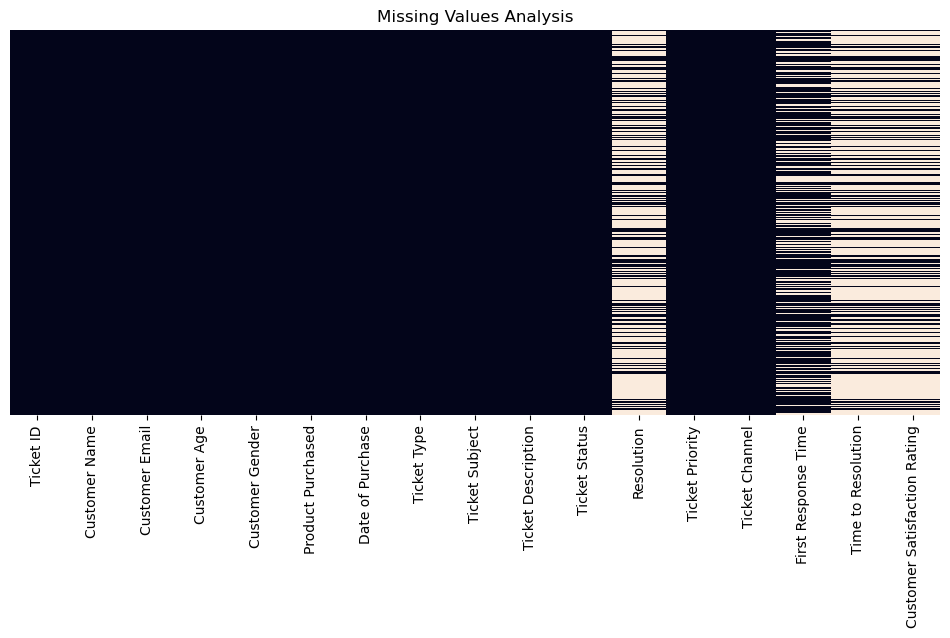

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values Analysis")
plt.show()

In [53]:
df.duplicated().sum()

np.int64(0)

In [54]:
df["Ticket ID"].duplicated().sum()

np.int64(0)

In [55]:
df[df["Ticket ID"].duplicated(keep=False)].sort_values("Ticket ID")

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating


In [56]:
df.dtypes

Ticket ID                         int64
Customer Name                    object
Customer Email                   object
Customer Age                      int64
Customer Gender                  object
Product Purchased                object
Date of Purchase                 object
Ticket Type                      object
Ticket Subject                   object
Ticket Description               object
Ticket Status                    object
Resolution                       object
Ticket Priority                  object
Ticket Channel                   object
First Response Time              object
Time to Resolution               object
Customer Satisfaction Rating    float64
dtype: object

In [57]:
df1 = df.copy()

df1["Ticket ID"] = (
    pd.to_numeric(df1["Ticket ID"])
    .map(lambda x: f"T-{x:03.0f}")
    .astype("string")
)

In [58]:
df1["Date of Purchase"] = pd.to_datetime(
    df1["Date of Purchase"],
    format="%d-%m-%Y",
    errors="coerce"
)

In [59]:
df1["Date of Purchase"].dtype

dtype('<M8[ns]')

In [60]:
date_columns = [
    "First Response Time",
    "Time to Resolution"
]

for col in date_columns:
    df1[col] = pd.to_datetime(
        df1[col],
        format="%d-%m-%Y %H:%M",
        errors="coerce"
    )

In [61]:
df1[date_columns].dtypes

First Response Time    datetime64[ns]
Time to Resolution     datetime64[ns]
dtype: object

In [62]:
status_check = (
    df1.groupby("Ticket Status")
    ["Time to Resolution"]
    .agg(
        Total="count",
    )
)

In [63]:
status_check = (
    df1.assign(
        resolution_missing=df1["Time to Resolution"].isna()
    )
    .groupby("Ticket Status")
    .agg(
        Total_Tickets=("Ticket ID", "count"),
        Missing_Resolution=("resolution_missing", "sum")
    )
)

status_check["Missing_Percentage"] = (
    status_check["Missing_Resolution"]
    / status_check["Total_Tickets"] * 100
).round(2)

status_check

,Total_Tickets,Missing_Resolution,Missing_Percentage
Ticket Status,,,
Closed,2769,0,0.0
Open,2819,2819,100.0
Pending Customer Response,2881,2881,100.0


In [64]:
df1.dtypes

Ticket ID                       string[python]
Customer Name                           object
Customer Email                          object
Customer Age                             int64
Customer Gender                         object
Product Purchased                       object
Date of Purchase                datetime64[ns]
Ticket Type                             object
Ticket Subject                          object
Ticket Description                      object
Ticket Status                           object
Resolution                              object
Ticket Priority                         object
Ticket Channel                          object
First Response Time             datetime64[ns]
Time to Resolution              datetime64[ns]
Customer Satisfaction Rating           float64
dtype: object

In [65]:
categorical_columns = [
    "Customer Gender",
    "Product Purchased",
    "Ticket Type",
    "Ticket Status",
    "Ticket Priority",
    "Ticket Channel"
]

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


Customer Gender
Customer Gender
Male      2896
Female    2887
Other     2686
Name: count, dtype: int64

Product Purchased
Product Purchased
Canon EOS                         240
GoPro Hero                        228
Nest Thermostat                   225
Philips Hue Lights                221
Amazon Echo                       221
LG Smart TV                       219
Sony Xperia                       217
Roomba Robot Vacuum               216
Apple AirPods                     213
LG OLED                           213
iPhone                            212
Sony 4K HDR TV                    210
Garmin Forerunner                 208
LG Washing Machine                208
Canon DSLR Camera                 206
Nikon D                           204
Nintendo Switch Pro Controller    203
Google Pixel                      203
Fitbit Charge                     202
Sony PlayStation                  202
HP Pavilion                       200
Microsoft Office                  200
Amazon Kindle          

In [66]:
df1["Ticket Status"] = df1["Ticket Status"].replace({
    "Pending Customer Response": "Pending"
})

In [67]:
numerical_columns = [
    "Customer Age",
    "Customer Satisfaction Rating"
]

for col in numerical_columns:
    print(f"\n{col}")
    print(df1[col].describe())


Customer Age
count    8469.000000
mean       44.026804
std        15.296112
min        18.000000
25%        31.000000
50%        44.000000
75%        57.000000
max        70.000000
Name: Customer Age, dtype: float64

Customer Satisfaction Rating
count    2769.000000
mean        2.991333
std         1.407016
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         5.000000
Name: Customer Satisfaction Rating, dtype: float64


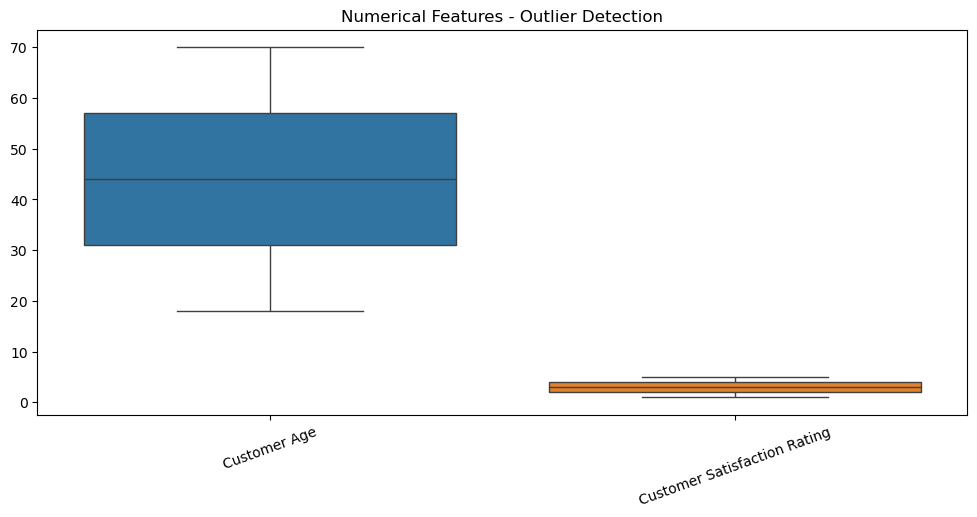

In [68]:
plt.figure(figsize=(12, 5))

sns.boxplot(data=df1[numerical_columns])

plt.title("Numerical Features - Outlier Detection")
plt.xticks(rotation=20)
plt.show()

In [69]:
print("Earliest Purchase Date:",
      df1["Date of Purchase"].min())

print("Latest Purchase Date:",
      df["Date of Purchase"].max())

Earliest Purchase Date: 2020-01-01 00:00:00
Latest Purchase Date: 31-12-2020


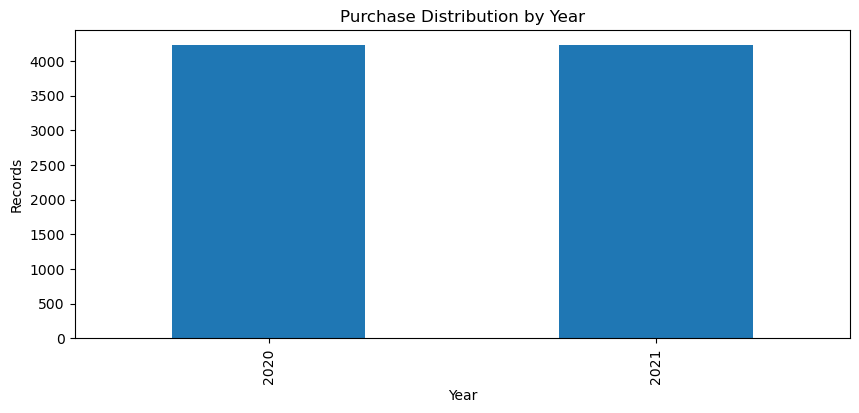

In [70]:
df1["Date of Purchase"].dt.year.value_counts().sort_index().plot(
    kind="bar",
    figsize=(10, 4)
)

plt.title("Purchase Distribution by Year")
plt.xlabel("Year")
plt.ylabel("Records")
plt.show()

In [71]:
text_columns = [
    "Ticket Subject",
    "Ticket Description",
    "Resolution"
]

for col in text_columns:
    empty_count = (
        df1[col].fillna("").str.strip().eq("").sum()
    )

    print(col, empty_count)

Ticket Subject 0
Ticket Description 0
Resolution 5700


In [72]:
df1["Description Length"] = (
    df1["Ticket Description"]
    .fillna("")
    .str.len()
)

df1["Description Length"].describe()

count    8469.000000
mean      289.821939
std        43.593954
min       151.000000
25%       273.000000
50%       298.000000
75%       318.000000
max       397.000000
Name: Description Length, dtype: float64

In [73]:
df1.head()

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating,Description Length
0,T-001,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending,NaN,Critical,Social media,2023-06-01 12:15:00,NaT,NaN,284
1,T-002,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending,NaN,Critical,Chat,2023-06-01 16:45:00,NaT,NaN,282
2,T-003,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:00,2023-06-01 18:05:00,3.0,275
3,T-004,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:00,2023-06-01 01:57:00,3.0,262
4,T-005,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:00,2023-06-01 19:53:00,1.0,333


In [74]:
selected_columns = [
    "Ticket ID",
    "Product Purchased",
    "Ticket Type",
    "Ticket Status",
    "Ticket Priority",
    "Ticket Channel",
    "First Response Time",
    "Time to Resolution",
    "Customer Satisfaction Rating"
]

analysis_df = df1[selected_columns].copy()

analysis_df.head()

,Ticket ID,Product Purchased,Ticket Type,Ticket Status,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,T-001,GoPro Hero,Technical issue,Pending,Critical,Social media,2023-06-01 12:15:00,NaT,NaN
1,T-002,LG Smart TV,Technical issue,Pending,Critical,Chat,2023-06-01 16:45:00,NaT,NaN
2,T-003,Dell XPS,Technical issue,Closed,Low,Social media,2023-06-01 11:14:00,2023-06-01 18:05:00,3.0
3,T-004,Microsoft Office,Billing inquiry,Closed,Low,Social media,2023-06-01 07:29:00,2023-06-01 01:57:00,3.0
4,T-005,Autodesk AutoCAD,Billing inquiry,Closed,Low,Email,2023-06-01 00:12:00,2023-06-01 19:53:00,1.0


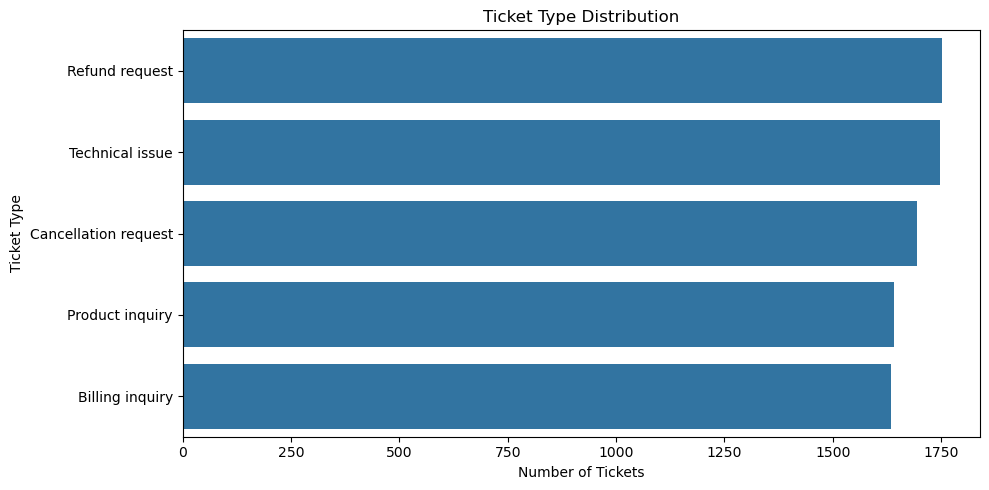

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Cleaned dataset ki copy
eda_df = analysis_df.copy()

plt.figure(figsize=(10, 5))

order = eda_df["Ticket Type"].value_counts().index

sns.countplot(
    data=eda_df,
    y="Ticket Type",
    order=order
)

plt.title("Ticket Type Distribution")
plt.xlabel("Number of Tickets")
plt.ylabel("Ticket Type")

plt.tight_layout()
plt.show()

In [76]:
type_summary = (
    eda_df["Ticket Type"]
    .value_counts()
    .to_frame("Ticket Count")
)

type_summary["Percentage"] = (
    type_summary["Ticket Count"]
    / len(eda_df) * 100
).round(2)

type_summary

,Ticket Count,Percentage
Ticket Type,,
Refund request,1752,20.69
Technical issue,1747,20.63
Cancellation request,1695,20.01
Product inquiry,1641,19.38
Billing inquiry,1634,19.29


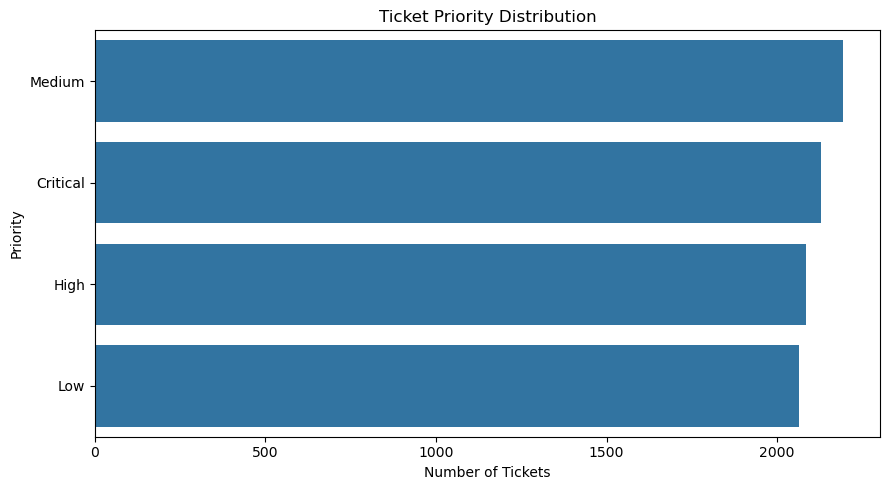

In [77]:
plt.figure(figsize=(9, 5))

order = eda_df["Ticket Priority"].value_counts().index

sns.countplot(
    data=eda_df,
    y="Ticket Priority",
    order=order
)

plt.title("Ticket Priority Distribution")
plt.xlabel("Number of Tickets")
plt.ylabel("Priority")

plt.tight_layout()
plt.show()

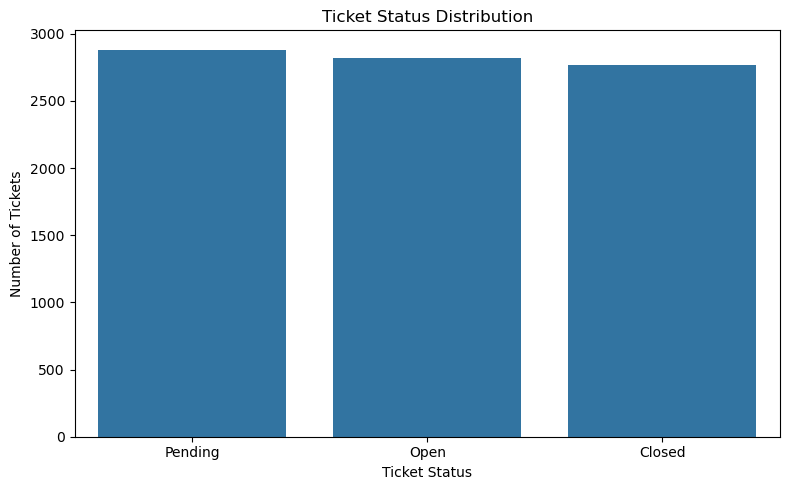

In [78]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=eda_df,
    x="Ticket Status",
    order=eda_df["Ticket Status"].value_counts().index
)

plt.title("Ticket Status Distribution")
plt.xlabel("Ticket Status")
plt.ylabel("Number of Tickets")

plt.tight_layout()
plt.show()

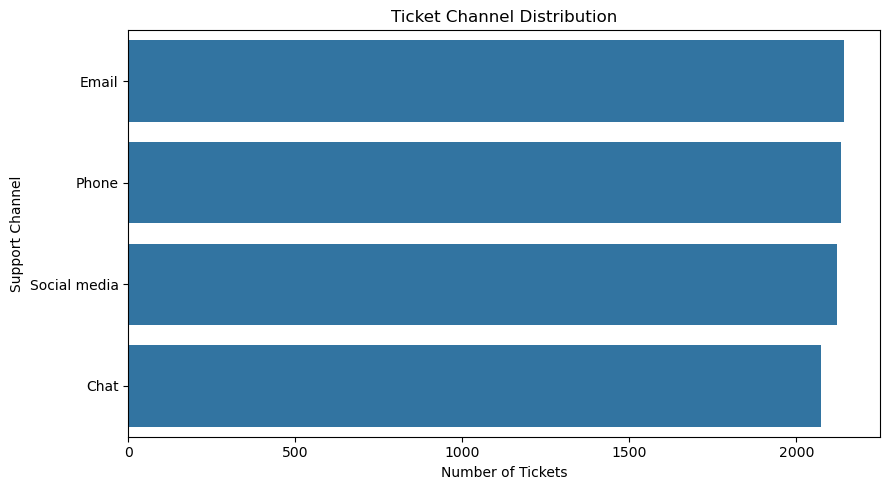

In [79]:
plt.figure(figsize=(9, 5))

order = eda_df["Ticket Channel"].value_counts().index

sns.countplot(
    data=eda_df,
    y="Ticket Channel",
    order=order
)

plt.title("Ticket Channel Distribution")
plt.xlabel("Number of Tickets")
plt.ylabel("Support Channel")

plt.tight_layout()
plt.show()

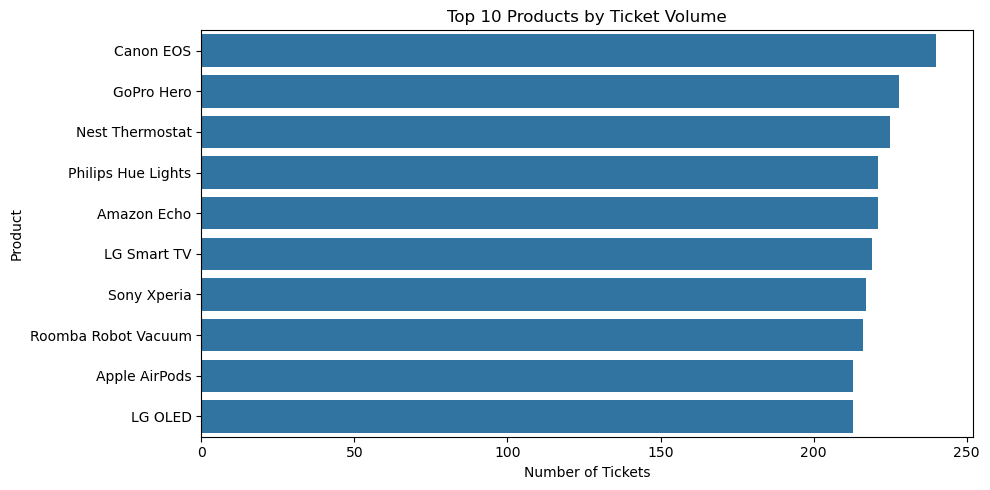

In [80]:
product_counts = (
    eda_df["Product Purchased"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=product_counts.values,
    y=product_counts.index
)

plt.title("Top 10 Products by Ticket Volume")
plt.xlabel("Number of Tickets")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

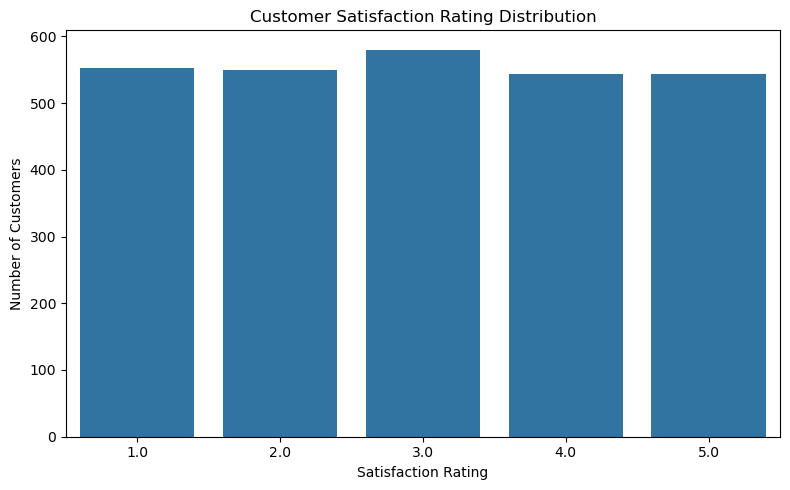

In [81]:
ratings = eda_df[
    "Customer Satisfaction Rating"
].dropna()

plt.figure(figsize=(8, 5))

sns.countplot(
    x=ratings,
    order=sorted(ratings.unique())
)

plt.title("Customer Satisfaction Rating Distribution")
plt.xlabel("Satisfaction Rating")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

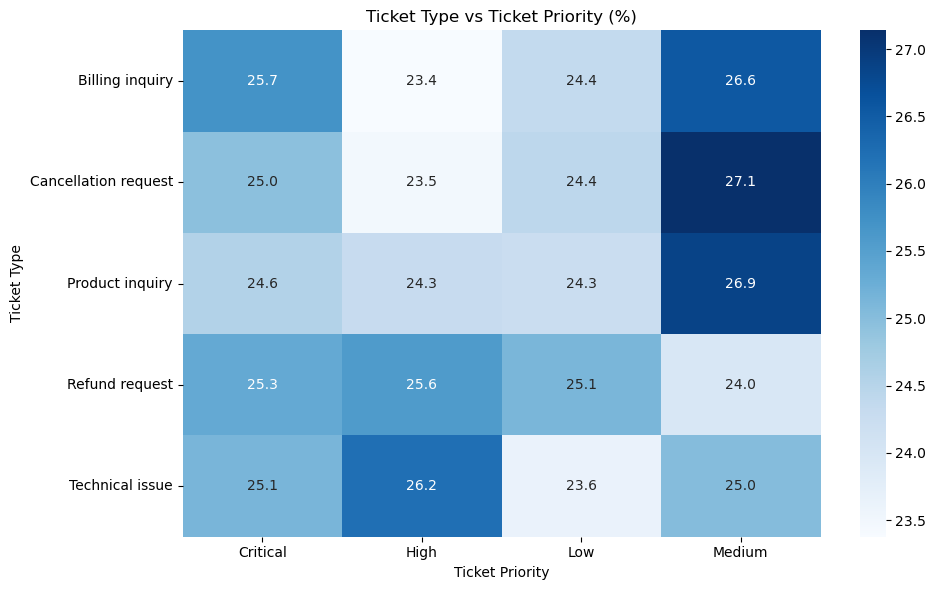

In [82]:
priority_mix = pd.crosstab(
    eda_df["Ticket Type"],
    eda_df["Ticket Priority"],
    normalize="index"
) * 100

plt.figure(figsize=(10, 6))

sns.heatmap(
    priority_mix,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Ticket Type vs Ticket Priority (%)")
plt.xlabel("Ticket Priority")
plt.ylabel("Ticket Type")

plt.tight_layout()
plt.show()

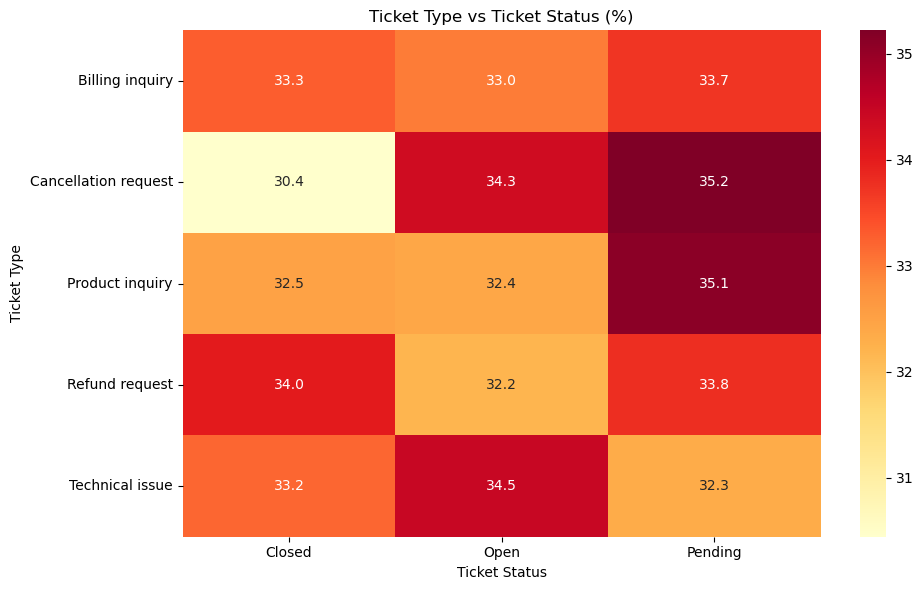

In [83]:
status_analysis = pd.crosstab(
    df1["Ticket Type"],
    df1["Ticket Status"],
    normalize="index"
) * 100

plt.figure(figsize=(10, 6))

sns.heatmap(
    status_analysis,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title("Ticket Type vs Ticket Status (%)")
plt.xlabel("Ticket Status")
plt.ylabel("Ticket Type")

plt.tight_layout()
plt.show()

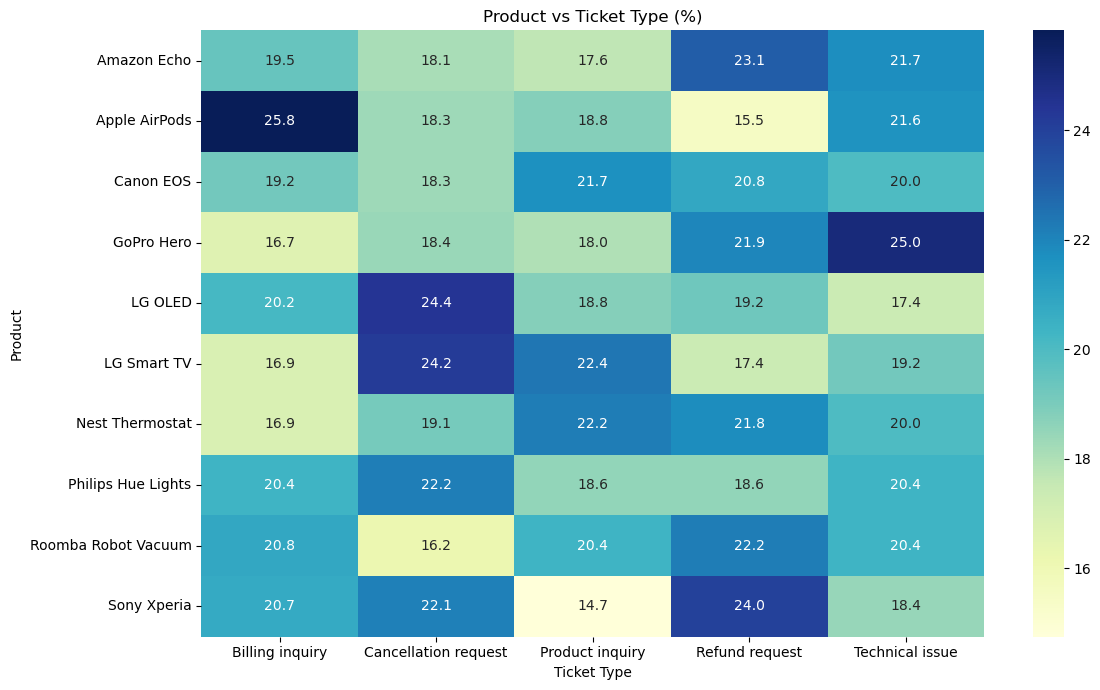

In [84]:
top_products = (
    df1["Product Purchased"]
    .value_counts()
    .head(10)
    .index
)

product_analysis_df = df1[
    df1["Product Purchased"].isin(top_products)
]

product_type = pd.crosstab(
    product_analysis_df["Product Purchased"],
    product_analysis_df["Ticket Type"],
    normalize="index"
) * 100

plt.figure(figsize=(12, 7))

sns.heatmap(
    product_type,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Product vs Ticket Type (%)")
plt.xlabel("Ticket Type")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [85]:
from pathlib import Path

export_columns = [
    "Ticket ID",
    "Product Purchased",
    "Ticket Type",
    "Ticket Status",
    "Ticket Priority",
    "Ticket Channel",
    "First Response Time",
    "Time to Resolution",
    "Customer Satisfaction Rating"
]

historical_data = df1[export_columns].copy()

output_path = Path("customer_support_tickets_cleaned.csv")

historical_data.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Exported:", output_path.resolve())
print("Total records:", len(historical_data))

Exported: C:\Users\parth\Desktop\Customer_support_Ticket_analysis\Data-analysis\customer_support_tickets_cleaned.csv
Total records: 8469
